In [1]:
# ---- Environment check (for qBraid / fresh environments) ----
# Installs any missing package into THIS kernel's Python. Does nothing if all are present.
import importlib.util, subprocess, sys

REQUIRED = {  # import name -> pip requirement (versions tested with this notebook)
    "qiskit": "qiskit==2.2.3",
    "qiskit_aer": "qiskit-aer==0.17.2",
    "qiskit_nature": "qiskit-nature==0.8.0",
    "qiskit_algorithms": "qiskit-algorithms==0.4.0",
    "pyscf": "pyscf==2.15.0",
    "scipy": "scipy",
    "matplotlib": "matplotlib>=3.9",
}
missing = [req for mod, req in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Done. If imports below fail, restart the kernel and run all cells again.")
else:
    print("All required packages are installed.")

All required packages are installed.


In [2]:
# ======================================================================
# Challenge 01 - VQE: Ground-State Energy of H2
# Qiskit Fall Fest 2026 | Team Cdevi Code | Intermediate
# Goal: ground-state energy of H2 with VQE, verified against an exact result.
# Units: Hartree (Ha). Chemical accuracy = 1.6 mHa.
# Detailed explanations: docs/01..04 in the repository.
# ======================================================================
# ---- Section 0: Setup - imports and library versions ----

import numpy as np

import pyscf
import qiskit
import qiskit_nature
import qiskit_algorithms

# Chemistry -> Qiskit bridge
from qiskit_nature.units import DistanceUnit                         # lets us say "Angstrom" explicitly
from qiskit_nature.second_q.drivers import PySCFDriver               # runs PySCF for us
from qiskit_nature.second_q.mappers import JordanWignerMapper        # fermions -> qubits
from qiskit_nature.second_q.algorithms import GroundStateEigensolver # chemistry-aware solver wrapper

# Exact (classical) eigensolver used as our ground truth
from qiskit_algorithms import NumPyMinimumEigensolver

# Independent cross-check with PySCF's own Full Configuration Interaction (FCI) solver
from pyscf import gto, scf, fci

print(f"qiskit            {qiskit.__version__}")
print(f"qiskit-nature     {qiskit_nature.__version__}")
print(f"qiskit-algorithms {qiskit_algorithms.__version__}")
print(f"pyscf             {pyscf.__version__}")
print(f"numpy             {np.__version__}")

qiskit            2.2.3
qiskit-nature     0.8.0
qiskit-algorithms 0.4.0
pyscf             2.15.0
numpy             2.2.6


In [3]:
# ---- Section 1: Molecule - H2 at 0.735 A, STO-3G, neutral singlet (PySCF runs Hartree-Fock) ----

# --- Molecule specification -------------------------------------------------
BOND_LENGTH = 0.735  # Angstrom, close to the H2 equilibrium bond length

driver = PySCFDriver(
    atom=f"H 0 0 0; H 0 0 {BOND_LENGTH}",  # "element x y z; element x y z"
    basis="sto3g",                          # minimal basis: one 1s orbital per H atom
    charge=0,                               # neutral molecule -> 2 electrons
    spin=0,                                 # 2S = 0 -> all electrons paired (singlet)
    unit=DistanceUnit.ANGSTROM,             # coordinates above are in Angstrom
)

# driver.run() calls PySCF (Hartree-Fock + integrals) and packages everything
# into an ElectronicStructureProblem object.
problem = driver.run()

n_spatial = problem.num_spatial_orbitals   # number of molecular orbitals
n_alpha, n_beta = problem.num_particles    # (# spin-up electrons, # spin-down electrons)
nuclear_repulsion = problem.hamiltonian.nuclear_repulsion_energy
hf_energy = problem.reference_energy       # Hartree-Fock total energy

print(f"Spatial orbitals          : {n_spatial}")
print(f"Spin orbitals (= qubits)  : {2 * n_spatial}")
print(f"Electrons (alpha, beta)   : ({n_alpha}, {n_beta})")
print(f"Nuclear repulsion energy  : {nuclear_repulsion:.6f} Ha")
print(f"Hartree-Fock total energy : {hf_energy:.6f} Ha")

Spatial orbitals          : 2
Spin orbitals (= qubits)  : 4
Electrons (alpha, beta)   : (1, 1)
Nuclear repulsion energy  : 0.719969 Ha
Hartree-Fock total energy : -1.116999 Ha


In [4]:
# ---- Section 2: Electronic Hamiltonian (second quantisation), E_total = E_electronic + E_nuclear ----

# The fermionic (electron) Hamiltonian as a sum of creation/annihilation terms.
fermionic_op = problem.hamiltonian.second_q_op()

print(f"Number of fermionic terms: {len(fermionic_op)}")
print("First few terms (operator label -> coefficient in Ha):")
# '+_p' means a_p^dagger (create in spin-orbital p), '-_q' means a_q (destroy in q)
for label, coeff in list(fermionic_op.items())[:6]:
    print(f"  {label:<24} {coeff.real:+.6f}")

Number of fermionic terms: 36
First few terms (operator label -> coefficient in Ha):
  +_0 -_0                  -1.256339
  +_1 -_1                  -0.471896
  +_2 -_2                  -1.256339
  +_3 -_3                  -0.471896
  +_0 +_0 -_0 -_0          +0.337855
  +_0 +_1 -_1 -_0          +0.332291


In [5]:
# ---- Section 3: Jordan-Wigner mapping - one qubit per spin orbital ----
# Qubits 0-1 = spin-up, 2-3 = spin-down. Qiskit prints Pauli strings right-to-left (q3 q2 q1 q0).

mapper = JordanWignerMapper()

# Translate the fermionic Hamiltonian into a qubit Hamiltonian (a SparsePauliOp).
qubit_op = mapper.map(fermionic_op)

print(f"Qubits needed        : {qubit_op.num_qubits}")
print(f"Number of Pauli terms: {len(qubit_op)}\n")
print(f"{'Pauli string':>12}   coefficient (Ha)")
# Every coefficient must be real because the Hamiltonian is Hermitian (energies are real numbers).
for pauli, coeff in sorted(zip(qubit_op.paulis.to_labels(), qubit_op.coeffs), key=lambda t: -abs(t[1])):
    print(f"{pauli:>12}   {coeff.real:+.6f}")

assert np.allclose(qubit_op.coeffs.imag, 0), "Hamiltonian coefficients should be real"
print(f"\nHamiltonian is Hermitian: {np.allclose(qubit_op.to_matrix(), qubit_op.to_matrix().conj().T)}")

Qubits needed        : 4
Number of Pauli terms: 15

Pauli string   coefficient (Ha)
        IIII   -0.810548
        IIZI   -0.225753
        ZIII   -0.225753
        ZIZI   +0.174643
        IIIZ   +0.172184
        IZII   +0.172184
        IZIZ   +0.168928
        ZIIZ   +0.166145
        IZZI   +0.166145
        IIZZ   +0.120913
        ZZII   +0.120913
        YYYY   +0.045233
        XXYY   +0.045233
        YYXX   +0.045233
        XXXX   +0.045233

Hamiltonian is Hermitian: True


In [6]:
# ---- Section 4: Exact baseline - three independent methods must agree ----

# --- Method A: Qiskit's exact eigensolver -----------------------------------
exact_solver = GroundStateEigensolver(mapper, NumPyMinimumEigensolver())
exact_result = exact_solver.solve(problem)

E_electronic_exact = exact_result.groundenergy          # electronic part only
E_exact = exact_result.total_energies[0].real           # electronic + nuclear repulsion

# --- Method B: brute-force diagonalisation of the 16x16 qubit matrix ----------
eigenvalues = np.linalg.eigvalsh(qubit_op.to_matrix())  # eigvalsh: for Hermitian matrices, sorted ascending
E_numpy = eigenvalues[0] + nuclear_repulsion

# --- Method C: PySCF Full Configuration Interaction (no qubits involved) ------
mol = gto.M(atom=f"H 0 0 0; H 0 0 {BOND_LENGTH}", basis="sto-3g", charge=0, spin=0, unit="Angstrom")
mf = scf.RHF(mol).run(verbose=0)                        # restricted Hartree-Fock
E_fci = fci.FCI(mf).kernel()[0]                         # exact energy within the STO-3G basis

print(f"A. Qiskit NumPyMinimumEigensolver : {E_exact:.10f} Ha")
print(f"B. numpy eigvalsh (16x16 matrix)  : {E_numpy:.10f} Ha")
print(f"C. PySCF FCI                      : {E_fci:.10f} Ha")

# All three must agree to (essentially) machine precision.
assert abs(E_exact - E_numpy) < 1e-8 and abs(E_exact - E_fci) < 1e-8, "Exact methods disagree!"
print("\nAll three exact methods agree (|difference| < 1e-8 Ha).")

A. Qiskit NumPyMinimumEigensolver : -1.1373060358 Ha
B. numpy eigvalsh (16x16 matrix)  : -1.1373060358 Ha
C. PySCF FCI                      : -1.1373060358 Ha

All three exact methods agree (|difference| < 1e-8 Ha).


In [7]:
# Phase 1 result: exact energy and the correlation energy Hartree-Fock misses

correlation_energy = E_exact - hf_energy

print(f"Hartree-Fock energy (mean field)  : {hf_energy:.6f} Ha")
print(f"Exact ground-state energy (FCI)   : {E_exact:.6f} Ha")
print(f"Correlation energy (Exact - HF)   : {correlation_energy * 1000:.3f} mHa")
print(f"Chemical-accuracy target          : 1.600 mHa")
print(f"\nThe VQE answer must land within 1.6 mHa of {E_exact:.6f} Ha "
      "to count as chemically accurate.")

Hartree-Fock energy (mean field)  : -1.116999 Ha
Exact ground-state energy (FCI)   : -1.137306 Ha
Correlation energy (Exact - HF)   : -20.307 mHa
Chemical-accuracy target          : 1.600 mHa

The VQE answer must land within 1.6 mHa of -1.137306 Ha to count as chemically accurate.


In [8]:
# ======================================================================
# PHASE 2: ANSATZ
# Section 5: VQE minimises E(theta) = <psi(theta)|H|psi(theta)> >= E0 (variational principle).
# We use a UCCSD ansatz (details: docs/02_ansatz.md).
# ======================================================================

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector                 # named, tunable circuit angles
from qiskit.circuit.library import PauliEvolutionGate      # implements exp(-i * t * G) for a Pauli-sum G
from qiskit.quantum_info import Statevector
from qiskit_nature.second_q.operators import FermionicOp
from qiskit_nature.second_q.circuit.library.ansatzes.utils import generate_fermionic_excitations
import matplotlib.pyplot as plt


def total_energy(circuit: QuantumCircuit) -> float:
    '''Exact energy <psi|H|psi> + nuclear repulsion for a circuit with no free parameters.

    Uses an ideal (noise-free, infinite-shot) statevector simulation, so the result is exact.
    .decompose() first expands high-level gates (e.g. evolution gates) into elementary
    rotations + CNOTs, i.e. the circuit a quantum computer would actually run.
    '''
    psi = Statevector(circuit.decompose())
    return psi.expectation_value(qubit_op).real + nuclear_repulsion

In [9]:
# ---- Section 6: Hartree-Fock state - X gates on qubits 0 and 2 -> |0101> ----

hf_circuit = QuantumCircuit(4, name="HF")
hf_circuit.x(0)   # spin-up electron in the bonding orbital
hf_circuit.x(2)   # spin-down electron in the bonding orbital
print(hf_circuit.draw())

hf_state = Statevector(hf_circuit)
print("Basis state(s) present:", {k: round(float(v), 6) for k, v in hf_state.probabilities_dict().items()})

E_hf_circuit = total_energy(hf_circuit)
print(f"\nEnergy of HF circuit       : {E_hf_circuit:.10f} Ha")
print(f"PySCF Hartree-Fock energy  : {hf_energy:.10f} Ha")
assert abs(E_hf_circuit - hf_energy) < 1e-8
print("Match: our 2-gate circuit really is the Hartree-Fock state.")

     ┌───┐
q_0: ┤ X ├
     └───┘
q_1: ─────
     ┌───┐
q_2: ┤ X ├
     └───┘
q_3: ─────
          
Basis state(s) present: {np.str_('0101'): 1.0}

Energy of HF circuit       : -1.1169989968 Ha
PySCF Hartree-Fock energy  : -1.1169989968 Ha
Match: our 2-gate circuit really is the Hartree-Fock state.


In [10]:
# ---- Section 7: Excitations - singles + double, each mapped to G_k = i(T_k - T_k^dagger) ----

# Which excitations conserve electron number and spin? Qiskit Nature enumerates them for us.
singles = generate_fermionic_excitations(1, n_spatial, (n_alpha, n_beta))
doubles = generate_fermionic_excitations(2, n_spatial, (n_alpha, n_beta))
excitations = singles + doubles
print("Excitations (from occupied spin-orbitals) -> (to empty spin-orbitals):")
for occ, unocc in excitations:
    kind = "single" if len(occ) == 1 else "double"
    print(f"  {kind}: {occ} -> {unocc}")

num_so = 2 * n_spatial
generators = []
for occ, unocc in excitations:
    # Fermionic label in Qiskit Nature's convention (same as its UCCSD class): '+_p' then '-_q'
    label = " ".join([f"+_{p}" for p in occ] + [f"-_{q}" for q in unocc])
    T = FermionicOp({label: 1.0}, num_spin_orbitals=num_so)
    # i(T - T^dagger) is Hermitian. Qiskit's evolution gate applies exp(-i*theta*G), so
    # exp(-i*theta*i(T - T^dagger)) = exp(theta*(T - T^dagger)), exactly the UCC unitary.
    G = mapper.map(1j * (T - T.adjoint())).simplify()
    generators.append(G)
    print(f"\n{label:<18} -> {len(G)} Pauli strings: {G.paulis.to_labels()}")

Excitations (from occupied spin-orbitals) -> (to empty spin-orbitals):
  single: (0,) -> (1,)
  single: (2,) -> (3,)
  double: (0, 2) -> (1, 3)

+_0 -_1            -> 2 Pauli strings: ['IIXY', 'IIYX']

+_2 -_3            -> 2 Pauli strings: ['XYII', 'YXII']

+_0 +_2 -_1 -_3    -> 8 Pauli strings: ['YYXY', 'XYYY', 'XXXY', 'YXYY', 'XYXX', 'YYYX', 'YXXX', 'XXYX']


In [11]:
# ---- Section 8: UCCSD circuit - HF state + one PauliEvolutionGate exp(-i theta_k G_k) per excitation ----

theta = ParameterVector("θ", len(generators))      # θ[0], θ[1], θ[2]
gate_labels = ["single α", "single β", "double"]   # same order as `excitations` above

ansatz = hf_circuit.copy(name="UCCSD")              # 1) start from |HF> = |0101>
for k, G in enumerate(generators):                  # 2) apply exp(-i θ_k G_k) for each excitation
    ansatz.append(PauliEvolutionGate(G, time=theta[k], label=gate_labels[k]), range(ansatz.num_qubits))

print(f"Qubits     : {ansatz.num_qubits}")
print(f"Parameters : {ansatz.num_parameters} -> {[p.name for p in ansatz.parameters]}")
print("\nHigh-level circuit (each box = one excitation exp(-i*theta*G)):")
print(ansatz.draw(fold=-1))

# Hardware view: decompose into CNOTs and single-qubit rotations
ansatz_hw = transpile(ansatz, basis_gates=["cx", "rz", "sx", "x"], optimization_level=1, seed_transpiler=7)
print(f"Transpiled gate counts : {dict(ansatz_hw.count_ops())}")
print(f"Transpiled depth       : {ansatz_hw.depth()}")

Qubits     : 4
Parameters : 3 -> ['θ[0]', 'θ[1]', 'θ[2]']

High-level circuit (each box = one excitation exp(-i*theta*G)):
     ┌───┐┌─────────────────┐┌─────────────────┐┌───────────────┐
q_0: ┤ X ├┤0                ├┤0                ├┤0              ├
     └───┘│                 ││                 ││               │
q_1: ─────┤1                ├┤1                ├┤1              ├
     ┌───┐│  single α(θ[0]) ││  single β(θ[1]) ││  double(θ[2]) │
q_2: ┤ X ├┤2                ├┤2                ├┤2              ├
     └───┘│                 ││                 ││               │
q_3: ─────┤3                ├┤3                ├┤3              ├
          └─────────────────┘└─────────────────┘└───────────────┘
Transpiled gate counts : {'rz': 58, 'cx': 56, 'sx': 31, 'x': 2}
Transpiled depth       : 91


In [12]:
# ---- Section 9: Validation - theta = 0 gives HF; matches Qiskit Nature UCCSD at random angles ----

import warnings
from qiskit_nature.second_q.circuit.library import UCCSD

# Check 1: zero angles -> Hartree-Fock
E_zero = total_energy(ansatz.assign_parameters([0.0, 0.0, 0.0]))
print(f"Check 1: E(theta = 0) = {E_zero:.10f} Ha  vs  HF = {hf_energy:.10f} Ha")
assert abs(E_zero - hf_energy) < 1e-8

# Check 2: agree with the library implementation at random angles
with warnings.catch_warnings():
    # The library UCCSD is built on Qiskit's deprecated NLocal class and triggers internal scipy
    # efficiency notices. We use it only as a reference, so its warnings are silenced in this block.
    warnings.simplefilter("ignore")
    reference_uccsd = UCCSD(n_spatial, (n_alpha, n_beta), mapper, initial_state=hf_circuit)

    rng = np.random.default_rng(seed=42)   # fixed seed -> reproducible
    max_diff = 0.0
    for _ in range(5):
        theta_test = rng.uniform(-1, 1, size=3)   # random angles in [-1, 1] rad
        E_ours = total_energy(ansatz.assign_parameters(theta_test))
        E_library = total_energy(reference_uccsd.assign_parameters(theta_test))
        max_diff = max(max_diff, abs(E_ours - E_library))
print(f"Check 2: max |E_ours - E_library| over 5 random theta = {max_diff:.1e} Ha")
assert max_diff < 1e-8
print("\nBoth checks passed: the ansatz is correct.")

Check 1: E(theta = 0) = -1.1169989968 Ha  vs  HF = -1.1169989968 Ha
Check 2: max |E_ours - E_library| over 5 random theta = 9.8e-15 Ha

Both checks passed: the ansatz is correct.


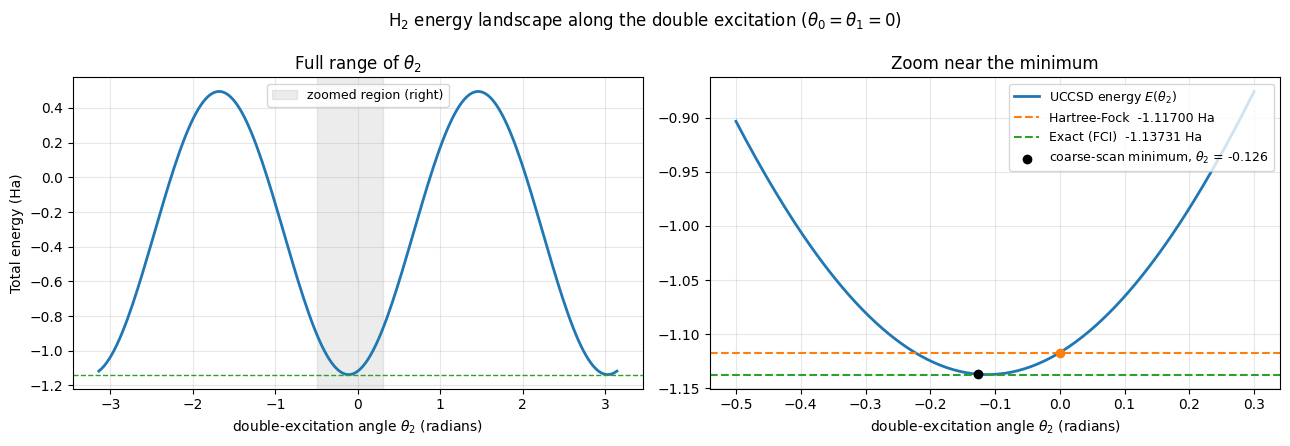

Best scanned energy : -1.136991 Ha at theta_2 = -0.1257 rad
Exact energy        : -1.137306 Ha
Gap (grid-limited)  : 0.3152 mHa


In [13]:
# ---- Section 10: Energy landscape along the double-excitation angle theta_2 ----

thetas = np.linspace(-np.pi, np.pi, 201)
landscape = [total_energy(ansatz.assign_parameters([0.0, 0.0, t])) for t in thetas]

i_min = int(np.argmin(landscape))
theta2_best, E_scan_best = thetas[i_min], landscape[i_min]

# Zoomed scan near the minimum, finer grid
thetas_zoom = np.linspace(-0.5, 0.3, 161)
landscape_zoom = [total_energy(ansatz.assign_parameters([0.0, 0.0, t])) for t in thetas_zoom]

fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: the full period, showing the overall shape
ax_full.plot(thetas, landscape, color="tab:blue", lw=2)
ax_full.axhline(E_exact, color="tab:green", ls="--", lw=1)
ax_full.axvspan(-0.5, 0.3, color="grey", alpha=0.15, label="zoomed region (right)")
ax_full.set_title(r"Full range of $\theta_2$")
ax_full.set_xlabel(r"double-excitation angle $\theta_2$ (radians)")
ax_full.set_ylabel("Total energy (Ha)")
ax_full.legend(loc="upper center", fontsize=9)
ax_full.grid(alpha=0.3)

# Right: zoom where HF and exact energies are visibly different (they differ by only ~20 mHa)
ax_zoom.plot(thetas_zoom, landscape_zoom, color="tab:blue", lw=2, label=r"UCCSD energy $E(\theta_2)$")
ax_zoom.axhline(hf_energy, color="tab:orange", ls="--", label=f"Hartree-Fock  {hf_energy:.5f} Ha")
ax_zoom.axhline(E_exact, color="tab:green", ls="--", label=f"Exact (FCI)  {E_exact:.5f} Ha")
ax_zoom.scatter([0.0], [hf_energy], color="tab:orange", zorder=5)
ax_zoom.scatter([theta2_best], [E_scan_best], color="black", zorder=5,
                label=rf"coarse-scan minimum, $\theta_2$ = {theta2_best:.3f}")
ax_zoom.set_title("Zoom near the minimum")
ax_zoom.set_xlabel(r"double-excitation angle $\theta_2$ (radians)")
ax_zoom.legend(loc="upper right", fontsize=9)
ax_zoom.grid(alpha=0.3)

fig.suptitle(r"H$_2$ energy landscape along the double excitation ($\theta_0=\theta_1=0$)")
plt.tight_layout()
plt.show()

print(f"Best scanned energy : {E_scan_best:.6f} Ha at theta_2 = {theta2_best:.4f} rad")
print(f"Exact energy        : {E_exact:.6f} Ha")
print(f"Gap (grid-limited)  : {(E_scan_best - E_exact) * 1000:.4f} mHa")

In [14]:
# ======================================================================
# PHASE 3: RUNNING VQE (details: docs/03_running_vqe.md)
# ======================================================================
# ---- Section 11: Estimator primitive and VQE cost function (ISA circuit, exact estimator) ----

from qiskit.primitives import StatevectorEstimator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from scipy.optimize import minimize

# Transpile the ansatz into gates the (Aer) backend supports -> "ISA" circuit
backend = AerSimulator()
pass_manager = generate_preset_pass_manager(optimization_level=1, backend=backend, seed_transpiler=7)
ansatz_isa = pass_manager.run(ansatz)
hamiltonian_isa = qubit_op.apply_layout(ansatz_isa.layout)   # keep qubit labels consistent

print(f"ISA circuit gate counts: {dict(ansatz_isa.count_ops())}")
print(f"ISA circuit parameters : {[p.name for p in ansatz_isa.parameters]}")


def make_cost_function(estimator):
    '''Build the function VQE minimises: theta -> total energy (Ha).

    Also returns a list that records every energy evaluation, so we can plot convergence.
    '''
    history = []

    def cost(theta):
        pub = (ansatz_isa, hamiltonian_isa, theta)          # (circuit, observable, parameter values)
        result = estimator.run([pub]).result()[0]           # one PUB in -> one result out
        energy = float(result.data.evs) + nuclear_repulsion # electronic energy + nuclear repulsion
        history.append(energy)
        return energy

    return cost, history


# Sanity check: at theta = 0 the estimator must return the Hartree-Fock energy
ideal_estimator = StatevectorEstimator()
cost_check, _ = make_cost_function(ideal_estimator)
E_check = cost_check(np.zeros(ansatz_isa.num_parameters))
print(f"\nEstimator at theta = 0 : {E_check:.10f} Ha (HF = {hf_energy:.10f} Ha)")
assert abs(E_check - hf_energy) < 1e-8

ISA circuit gate counts: {'cx': 56, 'u2': 25, 'rz': 12, 'h': 5, 'sxdg': 1}
ISA circuit parameters : ['θ[0]', 'θ[1]', 'θ[2]']

Estimator at theta = 0 : -1.1169989968 Ha (HF = -1.1169989968 Ha)


In [15]:
# ---- Section 12: VQE with three optimizers (SLSQP, L-BFGS-B, COBYLA), starting from HF ----

theta0 = np.zeros(ansatz_isa.num_parameters)   # start at the Hartree-Fock state
CHEM_ACC = 1.6e-3                                # chemical accuracy, in Ha

optimizer_settings = {
    "SLSQP":    {"maxiter": 200},
    "L-BFGS-B": {"maxiter": 200},
    "COBYLA":   {"maxiter": 500, "rhobeg": 0.1, "tol": 1e-8},   # rhobeg: initial step size (rad)
}

vqe_runs = {}
for name, options in optimizer_settings.items():
    cost, history = make_cost_function(StatevectorEstimator())
    result = minimize(cost, theta0, method=name, options=options)
    vqe_runs[name] = {"result": result, "history": history}

print(f"{'Optimizer':<10} {'E_VQE (Ha)':>15} {'Error (mHa)':>12} {'Evaluations':>12}   optimal theta (rad)")
for name, run in vqe_runs.items():
    r = run["result"]
    err_mHa = (r.fun - E_exact) * 1000
    print(f"{name:<10} {r.fun:>15.10f} {err_mHa:>12.2e} {len(run['history']):>12}   {np.round(r.x, 4)}")
    assert abs(r.fun - E_exact) < CHEM_ACC, f"{name} did not reach chemical accuracy"

print(f"\nExact (FCI) {E_exact:>15.10f}")
print("All three optimizers reach chemical accuracy.")

Optimizer       E_VQE (Ha)  Error (mHa)  Evaluations   optimal theta (rad)
SLSQP        -1.1373060357     5.74e-08           10   [ 0.      0.     -0.1118]
L-BFGS-B     -1.1373060358     3.86e-11           20   [ 0.     -0.     -0.1118]
COBYLA       -1.1373060358     1.20e-11           87   [-0.     -0.     -0.1118]

Exact (FCI)   -1.1373060358
All three optimizers reach chemical accuracy.


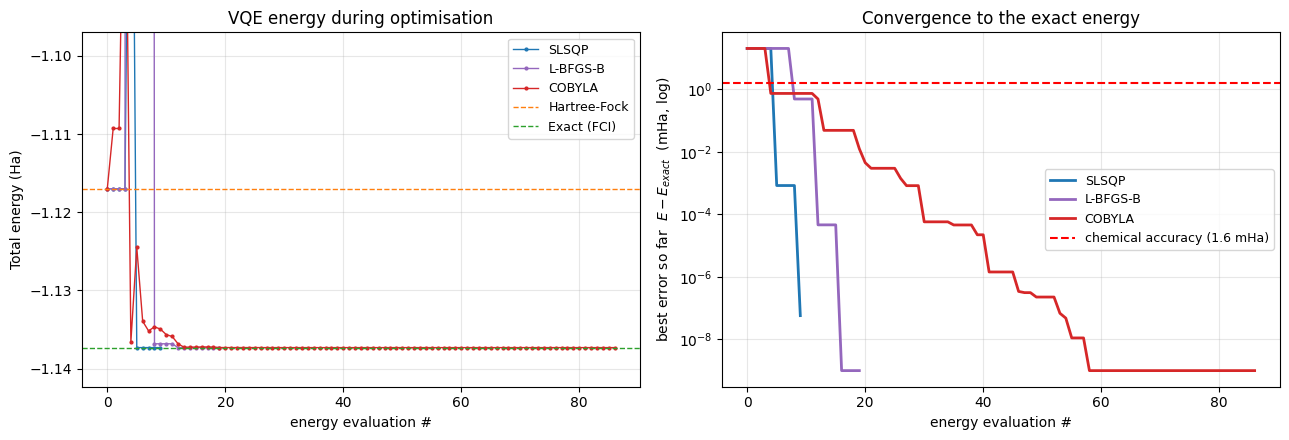

In [16]:
# ---- Section 13: Convergence plot ----

fig, (ax_e, ax_err) = plt.subplots(1, 2, figsize=(13, 4.5))
colors = {"SLSQP": "tab:blue", "L-BFGS-B": "tab:purple", "COBYLA": "tab:red"}

for name, run in vqe_runs.items():
    h = np.array(run["history"])
    ax_e.plot(h, color=colors[name], marker=".", ms=4, lw=1, label=name)
    # running best (lowest energy found so far); floor at 1e-12 so log scale works if error hits ~0
    best_so_far = np.minimum.accumulate(h)
    ax_err.semilogy(np.maximum(best_so_far - E_exact, 1e-12) * 1000, color=colors[name], lw=2, label=name)

ax_e.axhline(hf_energy, color="tab:orange", ls="--", lw=1, label="Hartree-Fock")
ax_e.axhline(E_exact, color="tab:green", ls="--", lw=1, label="Exact (FCI)")
ax_e.set_xlabel("energy evaluation #")
ax_e.set_ylabel("Total energy (Ha)")
ax_e.set_title("VQE energy during optimisation")
ax_e.set_ylim(E_exact - 0.005, hf_energy + 0.02)
ax_e.legend(fontsize=9)
ax_e.grid(alpha=0.3)

ax_err.axhline(CHEM_ACC * 1000, color="red", ls="--", label="chemical accuracy (1.6 mHa)")
ax_err.set_xlabel("energy evaluation #")
ax_err.set_ylabel(r"best error so far  $E - E_{exact}$  (mHa, log)")
ax_err.set_title("Convergence to the exact energy")
ax_err.legend(fontsize=9)
ax_err.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

In [17]:
# ---- Section 14: Optimal state - angles, composition, fidelity with exact ground state ----

best_name = min(vqe_runs, key=lambda n: vqe_runs[n]["result"].fun)
theta_opt = vqe_runs[best_name]["result"].x
E_vqe = vqe_runs[best_name]["result"].fun

print(f"Best run: {best_name}")
for k, label in enumerate(gate_labels):
    print(f"  theta[{k}] ({label:<8}) = {theta_opt[k]:+.5f} rad")

# State prepared by VQE (logical ansatz, decomposed to elementary gates)
psi_vqe = Statevector(ansatz.assign_parameters(theta_opt).decompose())
print("\nComposition of the VQE state (bitstring = q3 q2 q1 q0):")
for bitstring, p in sorted(psi_vqe.probabilities_dict().items(), key=lambda kv: -kv[1]):
    if p > 1e-6:
        print(f"  |{bitstring}>  probability {p:.5f}")

# Exact ground state: eigenvector of the 16x16 Hamiltonian matrix with the lowest eigenvalue
evals, evecs = np.linalg.eigh(qubit_op.to_matrix())
psi_exact = Statevector(evecs[:, 0])
fidelity = abs(np.vdot(psi_exact.data, psi_vqe.data)) ** 2
print(f"\nFidelity |<psi_exact|psi_VQE>|^2 = {fidelity:.10f}")
assert fidelity > 0.9999

Best run: COBYLA
  theta[0] (single α) = -0.00000 rad
  theta[1] (single β) = -0.00000 rad
  theta[2] (double  ) = -0.11177 rad

Composition of the VQE state (bitstring = q3 q2 q1 q0):
  |0101>  probability 0.98756
  |1010>  probability 0.01244

Fidelity |<psi_exact|psi_VQE>|^2 = 1.0000000000


In [18]:
# ---- Section 15: Cross-check with qiskit_algorithms.VQE ----

from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SLSQP as QiskitSLSQP

library_vqe = VQE(StatevectorEstimator(), ansatz_isa, QiskitSLSQP(maxiter=200), initial_point=theta0)
library_result = library_vqe.compute_minimum_eigenvalue(hamiltonian_isa)
E_library_vqe = library_result.eigenvalue.real + nuclear_repulsion   # library returns electronic energy only

print(f"qiskit_algorithms.VQE : {E_library_vqe:.10f} Ha  ({library_result.cost_function_evals} evaluations)")
print(f"Our VQE loop ({best_name}) : {E_vqe:.10f} Ha")
print(f"Exact (FCI)           : {E_exact:.10f} Ha")
assert abs(E_library_vqe - E_vqe) < 1e-6
print("\nThe library VQE agrees with our implementation.")

qiskit_algorithms.VQE : -1.1373060357 Ha  (10 evaluations)
Our VQE loop (COBYLA) : -1.1373060358 Ha
Exact (FCI)           : -1.1373060358 Ha

The library VQE agrees with our implementation.


In [19]:
# Phase 3 result table

error_mHa = (E_vqe - E_exact) * 1000
recovered = (hf_energy - E_vqe) / (hf_energy - E_exact) * 100

print("=" * 58)
print(f"{'H2 ground-state energy, STO-3G, R = 0.735 A':^58}")
print("=" * 58)
print(f"Hartree-Fock (mean field)      : {hf_energy:.8f} Ha")
vqe_label = f"VQE (UCCSD, {best_name})"
print(f"{vqe_label:<31}: {E_vqe:.8f} Ha")
print(f"Exact (FCI / diagonalisation)  : {E_exact:.8f} Ha")
print("-" * 58)
print(f"VQE error vs exact             : {error_mHa:.2e} mHa")
print(f"Chemical accuracy (1.6 mHa)?   : {'YES' if abs(error_mHa) < 1.6 else 'NO'}")
print(f"Correlation energy recovered   : {recovered:.4f} %")
print(f"State fidelity with exact      : {fidelity:.8f}")
print("=" * 58)

       H2 ground-state energy, STO-3G, R = 0.735 A        
Hartree-Fock (mean field)      : -1.11699900 Ha
VQE (UCCSD, COBYLA)            : -1.13730604 Ha
Exact (FCI / diagonalisation)  : -1.13730604 Ha
----------------------------------------------------------
VQE error vs exact             : 1.20e-11 mHa
Chemical accuracy (1.6 mHa)?   : YES
Correlation energy recovered   : 100.0000 %
State fidelity with exact      : 1.00000000


In [20]:
# ======================================================================
# PHASE 4: REALISTIC CONDITIONS (details: docs/04_noise_and_bond_curve.md)
# ======================================================================
# ---- Section 16: Shot noise - BackendEstimatorV2 on AerSimulator samples real shots ----

import itertools
from qiskit.primitives import BackendEstimatorV2

shot_backend = AerSimulator()                       # samples measurement outcomes shot by shot
shot_estimator = BackendEstimatorV2(backend=shot_backend)
seed_counter = itertools.count(start=2026)          # new seed per call -> independent but reproducible noise

groups = hamiltonian_isa.group_commuting(qubit_wise=True)
print(f"Hamiltonian: {len(hamiltonian_isa)} Pauli terms -> {len(groups)} measurement groups:")
for g in groups:
    print("   ", g.paulis.to_labels())


def noisy_energy(theta, shots):
    '''Total energy estimated from `shots` measurements per group (statistical noise included).'''
    shot_backend.set_options(seed_simulator=next(seed_counter))
    result = shot_estimator.run([(ansatz_isa, hamiltonian_isa, theta)], precision=1 / np.sqrt(shots)).result()[0]
    return float(result.data.evs) + nuclear_repulsion


def exact_energy(theta):
    '''Noise-free energy of the same circuit, which we use to judge the *true* quality of a theta.'''
    return float(StatevectorEstimator().run([(ansatz_isa, hamiltonian_isa, theta)]).result()[0].data.evs) + nuclear_repulsion


# Confirm the precision -> shots conversion
meta = shot_estimator.run([(ansatz_isa, hamiltonian_isa, theta_opt)], precision=1 / np.sqrt(10_000)).result()[0].metadata
print(f"\nprecision 1/sqrt(10000) -> shots per group used by the estimator: {meta['shots']}")

Hamiltonian: 15 Pauli terms -> 5 measurement groups:
    ['YYYY', 'IIII']
    ['XXYY']
    ['YYXX']
    ['XXXX']
    ['IIIZ', 'IIZI', 'IZII', 'ZIII', 'IIZZ', 'IZIZ', 'ZIIZ', 'IZZI', 'ZIZI', 'ZZII']

precision 1/sqrt(10000) -> shots per group used by the estimator: 10000


shots/group  mean error (mHa)  std dev (mHa)  within 1.6 mHa


        100            -4.401         15.948             10%


      1,000            -0.115          7.106             13%


     10,000            -0.235          1.791             60%


    100,000            +0.095          0.654            100%


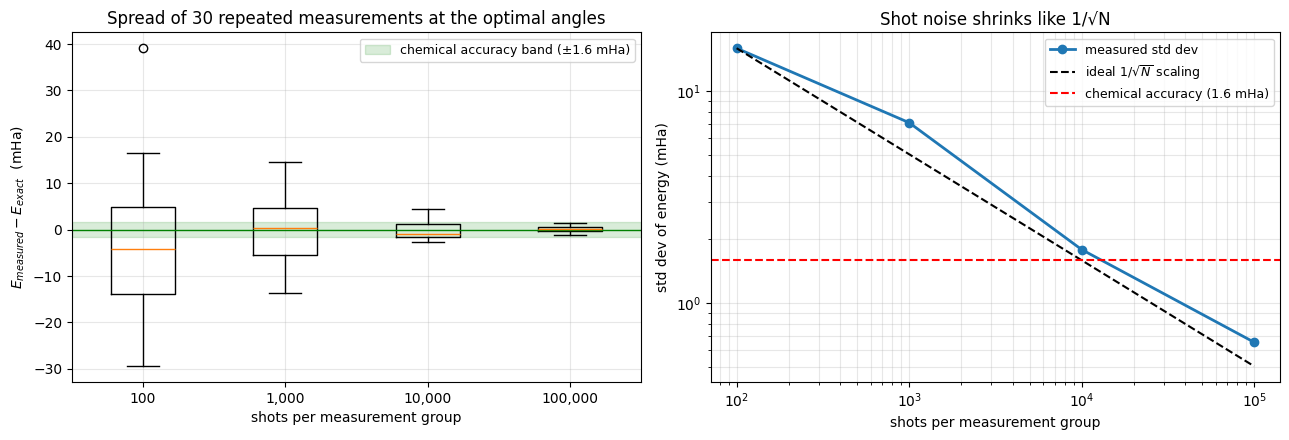

In [21]:
# Repeat the energy measurement 30x at the optimal angles for each shot count

shot_levels = [100, 1_000, 10_000, 100_000]
N_REPEATS = 30

noise_stats = {}
print(f"{'shots/group':>11} {'mean error (mHa)':>17} {'std dev (mHa)':>14} {'within 1.6 mHa':>15}")
for shots in shot_levels:
    samples = np.array([noisy_energy(theta_opt, shots) for _ in range(N_REPEATS)])
    errors_mHa = (samples - E_exact) * 1000
    noise_stats[shots] = errors_mHa
    frac_ok = np.mean(np.abs(errors_mHa) < 1.6) * 100
    print(f"{shots:>11,} {errors_mHa.mean():>+17.3f} {errors_mHa.std(ddof=1):>14.3f} {frac_ok:>14.0f}%")

fig, (ax_box, ax_std) = plt.subplots(1, 2, figsize=(13, 4.5))

ax_box.boxplot([noise_stats[s] for s in shot_levels], tick_labels=[f"{s:,}" for s in shot_levels])
ax_box.axhspan(-1.6, 1.6, color="green", alpha=0.15, label="chemical accuracy band (±1.6 mHa)")
ax_box.axhline(0, color="green", lw=1)
ax_box.set_xlabel("shots per measurement group")
ax_box.set_ylabel(r"$E_{measured} - E_{exact}$  (mHa)")
ax_box.set_title(f"Spread of {N_REPEATS} repeated measurements at the optimal angles")
ax_box.legend(fontsize=9, loc="upper right")
ax_box.grid(alpha=0.3)

stds = np.array([noise_stats[s].std(ddof=1) for s in shot_levels])
ax_std.loglog(shot_levels, stds, "o-", color="tab:blue", lw=2, label="measured std dev")
ref = stds[0] * np.sqrt(shot_levels[0] / np.array(shot_levels))   # ideal 1/sqrt(N) through first point
ax_std.loglog(shot_levels, ref, "k--", label=r"ideal $1/\sqrt{N}$ scaling")
ax_std.axhline(1.6, color="red", ls="--", label="chemical accuracy (1.6 mHa)")
ax_std.set_xlabel("shots per measurement group")
ax_std.set_ylabel("std dev of energy (mHa)")
ax_std.set_title("Shot noise shrinks like 1/√N")
ax_std.legend(fontsize=9)
ax_std.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

In [22]:
# ---- Section 17: Noisy VQE - SLSQP vs COBYLA vs SPSA, 10,000 shots/group, 3 seeded trials ----
# "True error" = final angles re-evaluated exactly (noise-free).

from qiskit_algorithms.optimizers import SPSA
from qiskit_algorithms.utils import algorithm_globals

NOISY_SHOTS = 10_000
N_TRIALS = 3


def run_noisy_vqe(optimizer_name, trial):
    '''One VQE run from HF with shot-noisy energies; returns reported/true energy and #evaluations.'''
    n_evals = [0]

    def cost(theta):
        n_evals[0] += 1
        return noisy_energy(theta, NOISY_SHOTS)

    if optimizer_name == "SPSA":
        algorithm_globals.random_seed = 100 + trial          # SPSA draws random perturbation directions
        spsa = SPSA(maxiter=100, learning_rate=0.05, perturbation=0.05)
        res = spsa.minimize(cost, theta0)
    elif optimizer_name == "COBYLA":
        res = minimize(cost, theta0, method="COBYLA", options={"maxiter": 200, "rhobeg": 0.1})
    else:  # SLSQP
        res = minimize(cost, theta0, method="SLSQP", options={"maxiter": 100})
    return {"reported": res.fun, "true": exact_energy(res.x), "evals": n_evals[0], "theta": res.x}


noisy_results = {name: [run_noisy_vqe(name, t) for t in range(N_TRIALS)] for name in ["SLSQP", "COBYLA", "SPSA"]}

print(f"{NOISY_SHOTS:,} shots per group per evaluation, {len(groups)} groups, starting from HF\n")
print(f"{'Optimizer':<8} {'trial':>5} {'reported err (mHa)':>19} {'TRUE err (mHa)':>15} {'evals':>6} {'total shots':>12}")
for name, runs in noisy_results.items():
    for t, r in enumerate(runs):
        total_shots = r["evals"] * len(groups) * NOISY_SHOTS
        print(f"{name:<8} {t:>5} {(r['reported'] - E_exact) * 1000:>+19.3f} "
              f"{(r['true'] - E_exact) * 1000:>15.3f} {r['evals']:>6} {total_shots:>12.1e}")
    print()

10,000 shots per group per evaluation, 5 groups, starting from HF

Optimizer trial  reported err (mHa)  TRUE err (mHa)  evals  total shots
SLSQP        0            +743.548         742.358    239      1.2e+07
SLSQP        1            +403.970         401.102    211      1.1e+07
SLSQP        2            +801.986         801.537    211      1.1e+07

COBYLA       0              +9.909           3.130     29      1.4e+06
COBYLA       1              +1.234           0.973     27      1.4e+06
COBYLA       2              +1.120           0.857     30      1.5e+06

SPSA         0              +0.522           0.013    201      1.0e+07
SPSA         1              -1.996           0.053    201      1.0e+07
SPSA         2              +0.143           0.018    201      1.0e+07



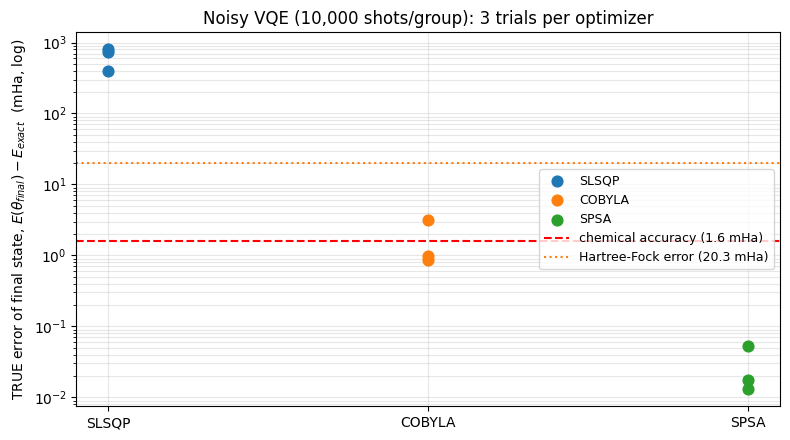

In [23]:
# Plot: true error of each noisy VQE run

fig, ax = plt.subplots(figsize=(8, 4.5))
names = list(noisy_results)
for i, name in enumerate(names):
    true_err = [(r["true"] - E_exact) * 1000 for r in noisy_results[name]]
    ax.scatter([i] * len(true_err), true_err, s=60, zorder=3, label=f"{name}")
ax.axhline(1.6, color="red", ls="--", label="chemical accuracy (1.6 mHa)")
ax.axhline(hf_energy * 1000 - E_exact * 1000, color="tab:orange", ls=":", label="Hartree-Fock error (20.3 mHa)")
ax.set_yscale("log")
ax.set_xticks(range(len(names)), names)
ax.set_ylabel(r"TRUE error of final state, $E(\theta_{final}) - E_{exact}$  (mHa, log)")
ax.set_title(f"Noisy VQE ({NOISY_SHOTS:,} shots/group): {N_TRIALS} trials per optimizer")
ax.legend(fontsize=9, loc="center right")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

In [24]:
# ---- Section 18: Potential-energy curve - HF, FCI and VQE for 25 bond lengths ----

bond_lengths = np.round(np.concatenate([np.arange(0.30, 1.00, 0.05), np.arange(1.0, 3.01, 0.20)]), 3)

pes = {"R": [], "hf": [], "fci": [], "vqe": [], "theta2": []}
theta_warm = np.zeros(ansatz_isa.num_parameters)

for R in bond_lengths:
    # 1) molecule + qubit Hamiltonian at this geometry (same settings as Section 1)
    prob_R = PySCFDriver(atom=f"H 0 0 0; H 0 0 {R}", basis="sto3g", charge=0, spin=0,
                         unit=DistanceUnit.ANGSTROM).run()
    H_R = mapper.map(prob_R.hamiltonian.second_q_op()).apply_layout(ansatz_isa.layout)
    E_nuc_R = prob_R.hamiltonian.nuclear_repulsion_energy

    # 2) exact reference: PySCF FCI (fixed 2 electrons, singlet)
    mf_R = scf.RHF(gto.M(atom=f"H 0 0 0; H 0 0 {R}", basis="sto-3g", unit="Angstrom")).run(verbose=0)
    E_fci_R = fci.FCI(mf_R).kernel()[0]

    # 3) ideal VQE, warm-started from the previous geometry's optimum
    def cost_R(theta):
        return float(StatevectorEstimator().run([(ansatz_isa, H_R, theta)]).result()[0].data.evs) + E_nuc_R
    res_R = minimize(cost_R, theta_warm, method="SLSQP", options={"maxiter": 200, "ftol": 1e-10})
    theta_warm = res_R.x

    pes["R"].append(R); pes["hf"].append(prob_R.reference_energy); pes["fci"].append(E_fci_R)
    pes["vqe"].append(res_R.fun); pes["theta2"].append(res_R.x[2])

pes = {k: np.array(v) for k, v in pes.items()}
vqe_err = np.abs(pes["vqe"] - pes["fci"]) * 1000
i_eq = int(np.argmin(pes["vqe"]))
print(f"Scanned {len(bond_lengths)} bond lengths from {bond_lengths[0]} to {bond_lengths[-1]} A")
print(f"Max |VQE - FCI| over the whole curve : {vqe_err.max():.2e} mHa")
print(f"Max |HF  - FCI| over the whole curve : {np.max(pes['hf'] - pes['fci']) * 1000:.1f} mHa (at R = {pes['R'][np.argmax(pes['hf'] - pes['fci'])]} A)")
print(f"VQE equilibrium bond length (grid)   : {pes['R'][i_eq]} A  (experiment ~0.741 A)")
assert vqe_err.max() < 1.6, "VQE lost chemical accuracy somewhere on the curve"

# Bond dissociation energy: E(far apart) - E(equilibrium), in the minimal basis
D_e = (pes["vqe"][-1] - pes["vqe"][i_eq]) * 27.2114
print(f"Bond energy estimate E(3.0 A) - E(eq): {D_e:.2f} eV  (STO-3G; experiment ~4.75 eV)")

Scanned 25 bond lengths from 0.3 to 3.0 A
Max |VQE - FCI| over the whole curve : 3.34e-08 mHa
Max |HF  - FCI| over the whole curve : 277.6 mHa (at R = 3.0 A)
VQE equilibrium bond length (grid)   : 0.75 A  (experiment ~0.741 A)
Bond energy estimate E(3.0 A) - E(eq): 5.54 eV  (STO-3G; experiment ~4.75 eV)


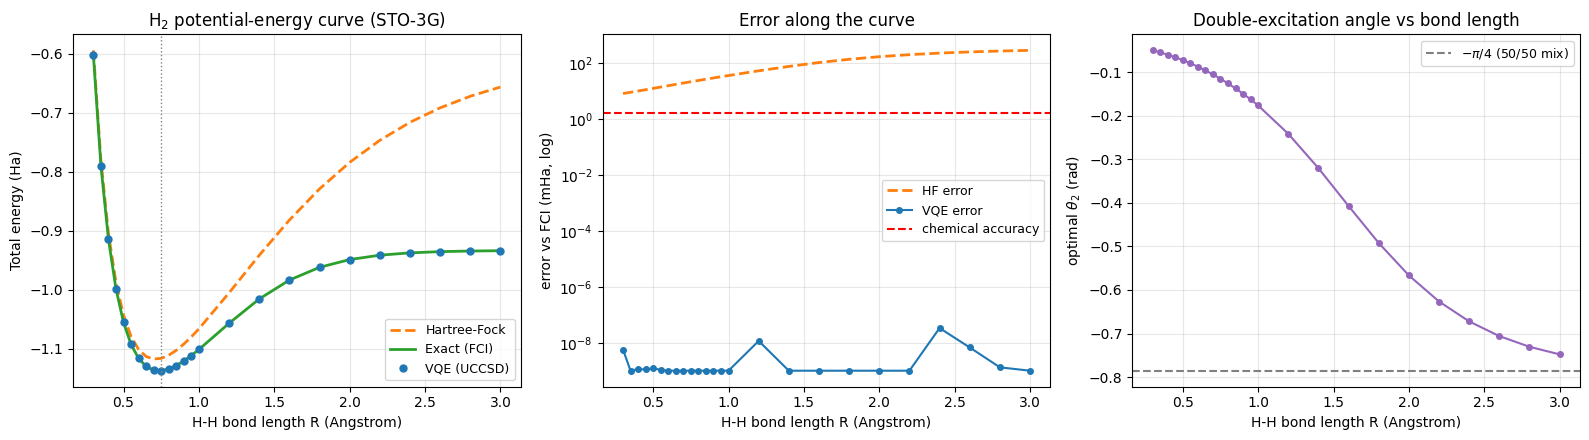

In [25]:
# Plot: energy curve, error along the curve, optimal theta_2 vs bond length

fig, (ax_pes, ax_err, ax_th) = plt.subplots(1, 3, figsize=(16, 4.5))

ax_pes.plot(pes["R"], pes["hf"], "--", color="tab:orange", lw=2, label="Hartree-Fock")
ax_pes.plot(pes["R"], pes["fci"], "-", color="tab:green", lw=2, label="Exact (FCI)")
ax_pes.plot(pes["R"], pes["vqe"], "o", color="tab:blue", ms=5, label="VQE (UCCSD)")
ax_pes.axvline(pes["R"][i_eq], color="grey", ls=":", lw=1)
ax_pes.set_xlabel("H-H bond length R (Angstrom)")
ax_pes.set_ylabel("Total energy (Ha)")
ax_pes.set_title(r"H$_2$ potential-energy curve (STO-3G)")
ax_pes.legend(fontsize=9)
ax_pes.grid(alpha=0.3)

ax_err.semilogy(pes["R"], (pes["hf"] - pes["fci"]) * 1000, "--", color="tab:orange", lw=2, label="HF error")
ax_err.semilogy(pes["R"], np.maximum(vqe_err, 1e-9), "o-", color="tab:blue", ms=4, label="VQE error")
ax_err.axhline(1.6, color="red", ls="--", label="chemical accuracy")
ax_err.set_xlabel("H-H bond length R (Angstrom)")
ax_err.set_ylabel("error vs FCI (mHa, log)")
ax_err.set_title("Error along the curve")
ax_err.legend(fontsize=9)
ax_err.grid(alpha=0.3, which="both")

ax_th.plot(pes["R"], pes["theta2"], "o-", color="tab:purple", ms=4)
ax_th.axhline(-np.pi / 4, color="grey", ls="--", label=r"$-\pi/4$ (50/50 mix)")
ax_th.set_xlabel("H-H bond length R (Angstrom)")
ax_th.set_ylabel(r"optimal $\theta_2$ (rad)")
ax_th.set_title("Double-excitation angle vs bond length")
ax_th.legend(fontsize=9)
ax_th.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:
# ======================================================================
# CONCLUSIONS
# - UCCSD-VQE reproduces the exact H2 energy, including at bond breaking where HF fails.
# - Under shot noise SPSA is robust; SLSQP fails.
# - Limitations: minimal STO-3G basis, no device noise model.
# ======================================================================

print("=" * 66)
print(f"{'FINAL RESULTS: H2 / STO-3G / Jordan-Wigner / UCCSD':^66}")
print("=" * 66)
print(f"Qubits / Pauli terms / ansatz parameters : {qubit_op.num_qubits} / {len(qubit_op)} / {ansatz.num_parameters}")
print(f"Exact ground-state energy (R = {BOND_LENGTH} A)  : {E_exact:.8f} Ha")
print(f"Ideal VQE energy                         : {E_vqe:.8f} Ha  (error {abs(E_vqe - E_exact) * 1000:.1e} mHa)")
spsa_true = [(r["true"] - E_exact) * 1000 for r in noisy_results["SPSA"]]
print(f"Noisy VQE, SPSA (true error)             : mean {np.mean(spsa_true):.3f} mHa ({N_TRIALS} trials, {NOISY_SHOTS:,} shots/group)")
print(f"Potential-energy curve, max VQE error    : {vqe_err.max():.1e} mHa over {len(bond_lengths)} geometries")
print(f"Chemical accuracy (1.6 mHa) achieved     : ideal YES | noisy SPSA "
      f"{'YES' if max(spsa_true) < 1.6 else 'NO'} | full curve {'YES' if vqe_err.max() < 1.6 else 'NO'}")
print("=" * 66)

        FINAL RESULTS: H2 / STO-3G / Jordan-Wigner / UCCSD        
Qubits / Pauli terms / ansatz parameters : 4 / 15 / 3
Exact ground-state energy (R = 0.735 A)  : -1.13730604 Ha
Ideal VQE energy                         : -1.13730604 Ha  (error 1.2e-11 mHa)
Noisy VQE, SPSA (true error)             : mean 0.028 mHa (3 trials, 10,000 shots/group)
Potential-energy curve, max VQE error    : 3.3e-08 mHa over 25 geometries
Chemical accuracy (1.6 mHa) achieved     : ideal YES | noisy SPSA YES | full curve YES
